In [1]:
using Pkg; Pkg.activate("..")

using Dates
using Statistics
using Interpolations
using ForwardDiff
using NCDatasets
using PythonPlot
using JLD2

using PythonCall

plt = pyimport("matplotlib.pyplot")
np = pyimport("numpy")
cc = pyimport("metpy.plots")
units = pyimport("metpy.units").units
mpc = pyimport("metpy.calc")

# Py method interprets Array{Union{T,Missing}} as a
# numpy masked array.
# This allows for plotting with missing values.
function PythonCall.Py(a::Array{Union{T,Missing},N}) where {T,N}
    np.ma.array(coalesce.(a,zero(T)), mask=ismissing.(a))
end

# use a sans family font like Arial, Helvetica, Open Sans
rc("font", family="sans-serif")
rc("font"; Symbol("sans-serif") => ["Arial", "Helvetica", "Open Sans"])
fontsize = 16                      # used for labels and ticks in all plot cells
rc("font", size=fontsize)

# user-defined local modules:
include(abspath("sonde_profiles.jl"))
include("sonde_averaging.jl"); using .SondeAveraging

  Activating project at `~/projects/ASTRAL/soundings`


In [2]:
if !isdefined(Main, :profs)
    if !isfile("profs.jld2")
        # loads in ~1-2 min
        profs = all_profiles()[1]            # Revelle 2023, TGT 2024, IMD, Amini
        save("profs.jld2", "profs", profs)
    else
        # reloads in 12 s
        profs = load("profs.jld2")["profs"] 
    end
end


2292-element Vector{NamedTuple}:
 (source = "Revelle", station = "Revelle", time = DateTime("2023-06-17T00:00:00"), lat = 12.057, lon = 67.78558, p = [1008.4, 1007.3, 1006.2, 1005.0, 1003.9, 1002.8, 1001.6, 1000.5, 999.4, 998.3  …  44.5, 44.4, 44.3, 44.3, 44.2, 44.1, 44.1, 44.0, 43.9, 43.8], z = [20.0, 30.0, 40.0, 50.0, 60.0, 70.0, 80.0, 90.0, 100.0, 110.0  …  21460.0, 21470.0, 21480.0, 21490.0, 21500.0, 21510.0, 21520.0, 21530.0, 21540.0, 21550.0], θ = [296.14212870865083, 299.5275505373331, 301.4178000442756, 301.3207614701387, 301.3150691203746, 301.40936724271654, 301.3124809200088, 301.30700918878205, 301.4016254601972, 301.39632711649705  …  514.9965131557885, 516.0570514679644, 516.8760807608036, 516.8760807608036, 517.2095742686615, 517.3003168716309, 517.5440390468355, 517.8794801361325, 518.215902615054, 518.3091141376722], rh = [43.0, 47.0, 52.0, 61.0, 71.0, 76.0, 76.0, 76.0, 76.0, 77.0  …  2.0, 3.0, 4.0, 1.0, 2.0, 2.0, 2.0, 3.0, 1.0, 3.0], u = [0.45532281931361135, 6.166035

In [3]:
# select sondes from `months` in/adjacent to the Arabian Sea (default: May, west of 77.57°E)
function select_may_arabian_sea(profs; months=(5,), lonrange=(-Inf, 77.57), latrange=(-Inf, Inf),
                                 imd_keep=("kochi", "mangalore", "minicoy", "santacruz"))   # coastal/island IMD stations
    return filter( p -> month(p.time) in months && (p.source != "IMD" || p.station in imd_keep) &&
        lonrange[1] <= p.lon <= lonrange[2] && 
        latrange[1] <= p.lat <= latrange[2],
        profs )
end

as = select_may_arabian_sea(profs)
println(length(as), " of ", length(profs), " soundings in May over AS.")

218 of 2292 soundings in May over AS.


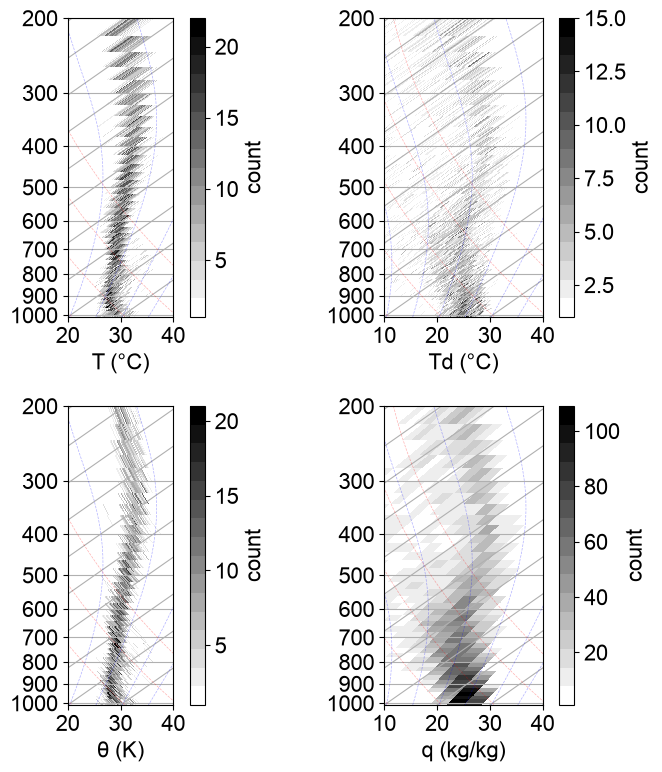

In [4]:
# histograms of T and Td (0.1 K), one realization per sounding, in 10 hPa bins, on skew-T log-p axes
pcenters=10.0:20.0:1020.0
halfwidth=10.0

hT = hist_field(as, :T; 
     dx=0.2, xlims=(-80.0, 40.0), pcenters=pcenters, halfwidth=halfwidth)
hTd = hist_field(as, :Td;
     dx=0.2, xlims=(-80.0, 40.0), pcenters=pcenters, halfwidth=halfwidth)
# q bins uniform in log q (about uniform in Td); linear bins put nearly all upper-air q in the lowest bin
qedges = 10 .^ range(-5, log10(0.03); length=41)      # 1e-5 to 3e-2 kg/kg
hq = hist_field(as, :q;
     edges=qedges, pcenters=pcenters, halfwidth=halfwidth)
hθ = hist_field(as, :θ; 
     dx=0.2, xlims=(280.0, 400.0), pcenters=pcenters, halfwidth=halfwidth)

ncolors = 16                          # number of discrete colors
cmap = get_cmap("gray_r", ncolors)

# the lowest pressure edge is 0 hPa (pcenters starts at 10, halfwidth 10): floor it so Td and log p stay finite
pedges = max.(hθ.pedges, 1.0)

# T edges for the θ histogram
# T [°C] at every (pressure edge, θ edge) corner: shape (np+1, nθ+1)
Tedge = hθ.xedges' .* (pedges ./ 1000) .^ κ .- 273.15
# Td edges for q histogram
# shape (np+1, nq+1) like Tedge; the q = 0 edge has no dewpoint, so floor it at qmin (a very cold Td)
qmin = 1e-6
Tdedge = [SondeAveraging.dewpoint(NaN, p; q=max(q, qmin)) for p in pedges, q in hq.xedges]
Pedge = pedges .* ones(1, length(hθ.xedges))   # same shape

plt.close("all")
fig = figure(figsize=(8, 8))
skewT  = cc.SkewT(fig; rotation=55, subplot=(2, 2, 1))
skewTd = cc.SkewT(fig; rotation=55, subplot=(2, 2, 2))
skewθ  = cc.SkewT(fig; rotation=55, subplot=(2, 2, 3))
skewq  = cc.SkewT(fig; rotation=55, subplot=(2, 2, 4))

function plotter(skew, h, Tedge, name)
     pe = max.(h.pedges, 1.0)
     # 2-D corner grids (θ, q panels) need a 2-D pressure grid of the same shape; 1-D edges (T, Td) do not
     P = Tedge isa AbstractMatrix ? pe .* ones(1, size(Tedge, 2)) : pe
     m = skew.ax.pcolormesh(Tedge, P, h.H'; cmap=cmap, vmin=1)   # h.H' is [level, bin], matching the edges
     skew.plot_dry_adiabats(alpha=0.3, linewidth=0.5)
     skew.plot_moist_adiabats(alpha=0.3, linewidth=0.5)
     skew.ax.set_ylim(1010, 200); skew.ax.set_xlim(20, 40)
     fig.colorbar(m; ax=skew.ax, label="count")
     skew.ax.set_xlabel(name; fontsize=fontsize)
     skew.ax.tick_params(axis="both"; labelsize=fontsize)   # xtick and ytick labels
end

plotter(skewθ, hθ, Tedge, "θ (K)")
plotter(skewT, hT, hT.xedges, "T (°C)")
plotter(skewTd, hTd, hTd.xedges, "Td (°C)")
plotter(skewq, hq, Tdedge, "q (kg/kg)")

skewTd.ax.set_xlim(10, 40)
skewq.ax.set_xlim(10, 40)

tight_layout()
gcf()

In [5]:
# θ histogram with the mean θ profile and a 40 °C dry adiabat (needs cell 3: hθ, Tedge, Pedge, cmap, pcenters, halfwidth)
mθ, σθ, nθ = SondeAveraging.mean_on_pgrid(as, :θ; pcenters=pcenters, halfwidth=halfwidth)   # unpacks mean, std, n
pc = collect(pcenters)
Tmean = mpc.temperature_from_potential_temperature(np.array(pc) * units.hPa, np.array(mθ) * units.K).to("degC")  # T of the mean θ [°C]

# 1. θ mode at each pressure level: center of the most populated θ bin of the histogram (NaN if empty)
θc = (hθ.xedges[1:end-1] .+ hθ.xedges[2:end]) ./ 2
θmode = [any(>(0), col) ? θc[argmax(col)] : NaN for col in eachcol(hθ.H)]
Tmode = mpc.temperature_from_potential_temperature(np.array(pc) * units.hPa, np.array(θmode) * units.K).to("degC")

# 2. mean pressure in each θ bin, over all (sounding, level) samples in the bin; bins with < nmin samples dropped
nmin = 5
w = vec(sum(hθ.H; dims=2))
pθ = ifelse.(w .>= nmin, (hθ.H * pc) ./ w, NaN)
Tpθ = mpc.temperature_from_potential_temperature(np.array(pθ) * units.hPa, np.array(θc) * units.K).to("degC")

t0 = np.array(20.0:10.0:80.0) .* units."degC"
tm0 = np.array(20.0:5.0:40.0) .* units."degC"
tmb = np.array([22.7, 26.0]) .* units."degC"
pad = collect(1010.0:-10.0:300.0)                         # dry adiabat that is 40 °C at 1000 hPa (θ = 313.15 K)

72-element Vector{Float64}:
 1010.0
 1000.0
  990.0
  980.0
  970.0
  960.0
  950.0
  940.0
  930.0
  920.0
    ⋮
  380.0
  370.0
  360.0
  350.0
  340.0
  330.0
  320.0
  310.0
  300.0

In [6]:
# wet-bulb potential temperature T0 [°C] at 1000 hPa of the moist adiabat whose saturation θe is θe [K]

# metpy saturation θe at 1000 hPa, T [K]: the residual being zeroed
θes1000(T) = pyconvert(Float64, mpc.saturation_equivalent_potential_temperature(1000 * units.hPa, T * units.K).m_as("K"))

"""
wet-bulb potential temperature T0 [°C] at 1000 hPa 
of the moist adiabat whose saturation θe is θe [K], 
"""
function t0_moist(θe; iters=2)
    # first guess: Davies-Jones (2008) closed form, as in metpy wet_bulb_potential_temperature
    x = θe / 273.15
    a = 7.101574 - 20.68208x + 16.11182x^2 + 2.574631x^3 - 5.205688x^4
    b = 1 - 3.552497x + 3.781782x^2 - 0.6899655x^3 - 0.5929340x^4
    T = θe <= 173.15 ? θe : θe - exp(a / b)

    # Newton slope: ForwardDiff of Bolton (1980) eq. 39 with Bolton es, at 1000 hPa
    # must expose as a Julia function to autodifferentiate.
    function θes_bolton(T)
        e = 6.112exp(17.67(T - 273.15) / (T - 29.65))
        r = 0.622e / (1000 - e)
        T * (1000 / (1000 - e))^κ * exp((3036 / T - 1.78) * r * (1 + 0.448r))
    end
    for _ in 1:iters
        T -= (θes1000(T) - θe) / ForwardDiff.derivative(θes_bolton, T)
    end
    T - 273.15
end

# for j in ext                                                  # moist adiabats through the θes extrema (cell 7)
#     t0 = t0_moist(θes[j])
#     println(pc[j], " hPa: θes = ", round(θes[j]; digits=2), " K → t0 = ", round(t0; digits=3),
#             " °C, residual ", round(θes1000(t0 + 273.15) - θes[j]; sigdigits=2), " K")
# end

t0_moist (generic function with 1 method)

In [7]:
# mean θe profile: θe of each sounding on the pressure grid, averaged over soundings
XT  = SondeAveraging.profiles_on_pgrid(as, :T;  pcenters=pcenters, halfwidth=halfwidth)   # [sounding, level] °C
XTd = SondeAveraging.profiles_on_pgrid(as, :Td; pcenters=pcenters, halfwidth=halfwidth)
Xθe = pyconvert(Matrix{Float64}, mpc.equivalent_potential_temperature(np.array(reshape(pc, 1, :)) * units.hPa,
          np.array(XT) * units.degC, np.array(XTd) * units.degC).m_as("K"))
mθe = SondeAveraging.colstats(Xθe).mean
# θe minimum in the troposphere (300-1000 hPa)
i0 = argmin([300 <= p <= 1000 && isfinite(θe) ? θe : Inf for (p, θe) in zip(pc, mθe)])
println("mean θe minimum: ", round(mθe[i0]; digits=1), " K at ", pc[i0], " hPa")

mean θe minimum: 337.2 K at 590.0 hPa


430.0 hPa: θes = 349.5 K  local max
550.0 hPa: θes = 347.79 K  local min


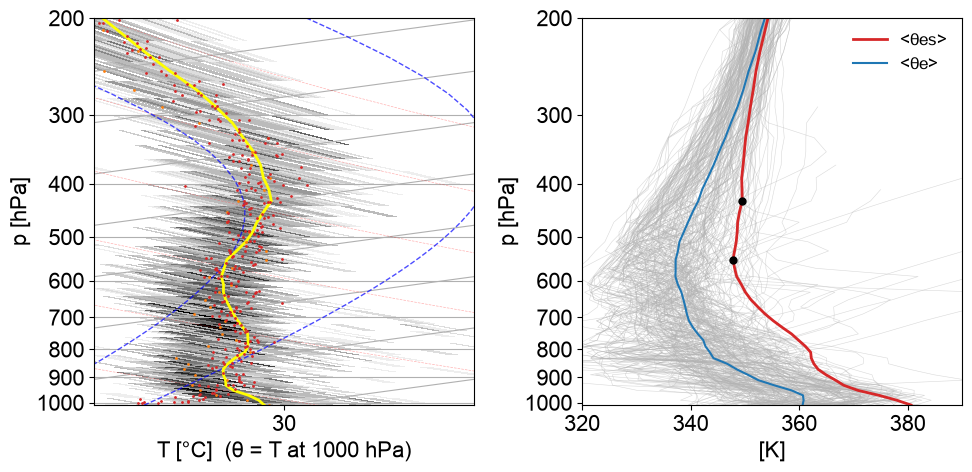

In [8]:
# theta_es labels the moist adiabat through the mean sounding at each level: θes(T̄(p), p), saturation θe of the mean T.
# Its extrema are where the mean sounding is parallel to a moist adiabat (dθ̄/dθm = 1). (needs cells 4-5: mθ, pc, mθe)
θes = pyconvert(Vector{Float64}, mpc.saturation_equivalent_potential_temperature(np.array(pc) * units.hPa,
          np.array(mθ .* (pc ./ 1000) .^ κ) * units.K).m_as("K"))
ext = [j for j in 2:length(pc)-1 if pc[j] >= 400 && (θes[j] - θes[j-1]) * (θes[j+1] - θes[j]) < 0]
for j in ext
    println(pc[j], " hPa: θes = ", round(θes[j]; digits=2), " K  local ", θes[j] < θes[j-1] ? "min" : "max")
end

plt.close("all")
wd, ht = 10, 5                                                 # figure width, height [in]
xl, yl = (25, 35), (1010, 200)                                 # skew-T limits: T [°C], p [hPa]
fig = figure(figsize=(wd, ht))
gs = fig.add_gridspec(1, 2; width_ratios=[1, 1])
# skew-T fills its slot (aspect "auto"); choose the rotation that keeps metpy's default data tilt of the
# isotherms, tan(55°)·80.5 °C per decade of p, for this box size and these limits
bb = gs[0].get_position(fig)
A = (pyconvert(Float64, bb.height) * ht / log10(yl[1] / yl[2])) / (pyconvert(Float64, bb.width) * wd / (xl[2] - xl[1]))
skewm = cc.SkewT(fig; rotation=atand(tand(55) * 80.5 / A), aspect="auto", subplot=gs[0])
C = float.(hθ.H); C[C .== 0] .= NaN
m = skewm.ax.pcolormesh(Tedge, Pedge, collect(C'); cmap=cmap, vmin=1)
skewm.plot_dry_adiabats(t0=t0, alpha=0.3, linewidth=0.5)
# moist adiabats (labeled by their temperature at 1000 hPa, °C): hot continental-air values
skewm.plot_moist_adiabats(t0=t0, color="C2", alpha=0.7, linewidth=1)
skewm.plot_moist_adiabats(t0=tm0, color="C2", alpha=0.7, linewidth=1)
skewm.plot_moist_adiabats(t0=tmb, alpha=0.7, linewidth=1)
# skewm.plot(pad, Tdry; color="C3", linewidth=2, label="40 °C dry adiabat (θ = 313 K)")
skewm.plot(pc, Tmean; color="yellow", linewidth=2, label="mean θ on p")
skewm.plot(pc, Tmode; color="C1", marker=".", markersize=2, linestyle="none", label="mode θ on p")
skewm.plot(pθ, Tpθ; color="C3", marker=".", markersize=2, linestyle="none", label="mean p on θ")
skewm.ax.set_ylim(yl...); skewm.ax.set_xlim(xl...)
# fig.colorbar(m; ax=skewm.ax, label="count")
skewm.ax.set_xlabel("T [°C]  (θ = T at 1000 hPa)"; fontsize=fontsize); skewm.ax.set_ylabel("p [hPa]"; fontsize=fontsize)
skewm.ax.tick_params(axis="both"; labelsize=fontsize)
# skewm.ax.legend(; fontsize=fontsize-2, frameon=false)

ax = fig.add_subplot(gs[1])
for row in eachrow(Xθe)                                       # θe of every sounding (metpy, cell 5)
    ax.plot(row, pc; color="0.7", linewidth=0.4, alpha=0.5)
end
ax.plot(θes, pc; color="C3", linewidth=2, label="<θes>")
ax.plot(mθe, pc; color="C0", linewidth=1.5, label="<θe>")
ax.plot(θes[ext], pc[ext], "ko"; markersize=5)
ax.set_yscale("log"); ax.set_ylim(yl...)
ax.set_xlim(320, 390)
ticks = [1000, 900, 800, 700, 600, 500, 400, 300, 200]
ax.set_yticks(ticks); ax.set_yticklabels(string.(ticks))
ax.set_xlabel("[K]"; fontsize=fontsize); ax.set_ylabel("p [hPa]"; fontsize=fontsize)
ax.tick_params(axis="both"; labelsize=fontsize)
ax.legend(; fontsize=fontsize-4, frameon=false)
fig.tight_layout()
gcf()

590.0-750.0 hPa: rms misfit 0.016 K, dF > 0 at θbot = [310.26565797824315, 312.90804226372154, 314.27151590779204, 317.08472020543115, 318.5346640507874, 321.5199752723275] K
810.0-1010.0 hPa: rms misfit 0.04 K, dF > 0 at θbot = [298.384013856732, 301.60363843589465, 302.7227113234709, 305.0347060934286, 306.2294446459214, 307.4512828639276, 308.7012267566734, 309.9803054801543] K
section 590-750 hPa:  θm(ptop) = 321.52 K,  θm(pbot) = 310.27 K
   θbot [K]     dF
   310.27    0.698
   312.91    0.012
   314.27    0.024
   317.08    0.043
   318.53    0.049
   321.52    0.174
section 810-1010 hPa:  θm(ptop) = 309.98 K,  θm(pbot) = 298.38 K
   θbot [K]     dF
   298.38    0.501
   301.6     0.017
   302.72    0.2
   305.03    0.014
   306.23    0.117
   307.45    0.053
   308.7     0.077
   309.98    0.021


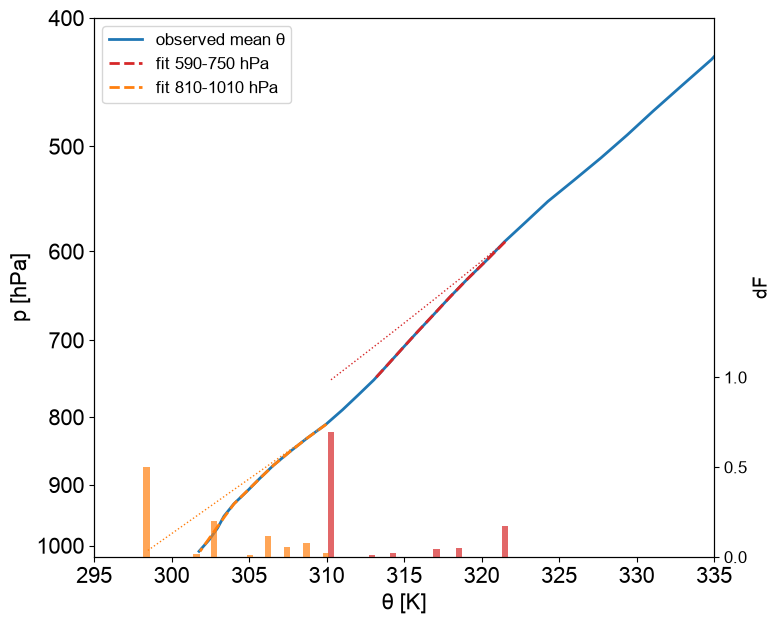

In [9]:
"nonnegative least squares min |Ax - b|, x ≥ 0 (Lawson & Hanson active set)"
function nnls(A, b; tol=1e-10)
    n = size(A, 2); x = zeros(n); P = falses(n)
    w = A' * (b - A * x)
    while any(.!P .& (w .> tol))
        P[argmax(ifelse.(P, -Inf, w))] = true
        while true
            z = zeros(n); z[P] = A[:, P] \ b
            all(z[P] .> 0) && (x = z; break)
            Q = P .& (z .<= 0)
            x .+= minimum(x[Q] ./ (x[Q] .- z[Q])) .* (z .- x)
            P .&= x .> tol
        end
        w = A' * (b - A * x)
    end
    x
end

"""
fit_dry_mixture(p, θ, ptop, pbot) -> (p, θm, θbot, dF, F, θfit)
Fit θ(p) on ptop ≤ p ≤ pbot by a mixture of soundings, each dry adiabatic (θ = θbot) from pbot up to where θbot meets
the moist adiabat θm through θ(ptop), and on θm above:  θfit(p) = Σ dF max(θbot, θm(p)).
Candidate θbot = θm at each level (the dry adiabat that meets θm there); dF ≥ 0, Σ dF = 1. F = cumsum(dF) from pbot up.
"""
function fit_dry_mixture(p, θ, ptop, pbot; wsum=1e3)
    k = findall(ptop .<= p .<= pbot)
    pk, θk = p[k], θ[k]
    j = argmin(pk)                                              # ptop level
    Tm = mpc.moist_lapse(np.array(pk) * units.hPa, θk[j] * (pk[j]/1000)^κ * units.K, pk[j] * units.hPa)
    θm = pyconvert(Vector{Float64}, mpc.potential_temperature(np.array(pk) * units.hPa, Tm).m_as("K"))
    M = [max(θb, θ_) for θ_ in θm, θb in θm]                    # [level, candidate θbot]
    dF = nnls([M; wsum * ones(1, length(θm))], [θk; wsum])      # Σ dF = 1 enforced by a heavy row
    o = sortperm(θm)                                            # from pbot up (increasing θbot)
    (p=pk, θm=θm, θbot=θm[o], dF=dF[o], F=cumsum(dF[o]), θfit=M * dF)
end

# re-fit the May Arabian Sea mean below the θe minimum, piecewise: p1 → pt and pt → surface,
# each section with its own moist adiabat through the mean θ at its top
fms = [fit_dry_mixture(pc, mθ, pc[i0], 750.0), fit_dry_mixture(pc, mθ, 810.0, 1010.0)]
for f in fms
    println(f.p[1], "-", f.p[end], " hPa: rms misfit ", round(sqrt(mean((f.θfit .- mθ[f.p[1] .<= pc .<= f.p[end]]) .^ 2)); digits=3),
            " K, dF > 0 at θbot = ", f.θbot[f.dF .> 1e-6], " K")
end
for f in fms                                                  # θm at ptop and pbot; dF > 0 at their θbot
    println("section ", Int(f.p[1]), "-", Int(f.p[end]), " hPa:  θm(ptop) = ", round(f.θm[1]; digits=2),
            " K,  θm(pbot) = ", round(f.θm[end]; digits=2), " K")
    println("   θbot [K]     dF")
    for k in findall(>(1e-6), f.dF)
        println("   ", rpad(round(f.θbot[k]; digits=2), 10), round(f.dF[k]; digits=3))
    end
end

plt.close("all")
fig, ax = subplots(figsize=(8, 7))
ax.plot(mθ, pc; color="C0", linewidth=2, label="observed mean θ")
for (f, c) in zip(fms, ("C3", "C1"))
    ax.plot(f.θfit, f.p; color=c, linestyle="--", linewidth=2, label="fit $(Int(f.p[1]))-$(Int(f.p[end])) hPa")
    ax.plot(f.θm, f.p; color=c, linestyle=":", linewidth=1)
end
ax.set_yscale("log"); ax.set_ylim(1020, 400); ax.set_xlim(295, 335)
ax.set_yticks([1000, 900, 800, 700, 600, 500, 400]); ax.set_yticklabels(string.([1000, 900, 800, 700, 600, 500, 400]))
ax.set_xlabel("θ [K]"; fontsize=fontsize); ax.set_ylabel("p [hPa]"; fontsize=fontsize)
ax.tick_params(axis="both"; labelsize=fontsize)
ax.legend(; loc="upper left", fontsize=fontsize-4)
axd = ax.twinx()                                            # dF at θbot, along the bottom third
for (f, c) in zip(fms, ("C3", "C1"))
    axd.bar(f.θbot, f.dF; width=0.4, color=c, alpha=0.7)
end
axd.set_ylim(0, 3); axd.set_yticks([0.0, 0.5, 1.0]); axd.set_ylabel("dF"; fontsize=fontsize-2)
axd.tick_params(axis="y"; labelsize=fontsize-4)
gcf()

When the potential temperature curves down (concave down) and is less stable than the moist adiabat, it can be explained by mixing of warmer dry adiabats from below.

Two layers indicate dry adiabatic mixing:
1. a (298 K, 1010 hPa) moist adiabat mixing with 302-310 K potential-temperature air
2. a (310 K,  750 hPa) moist adiabat mixing with 312-322 K potential-temperature air.

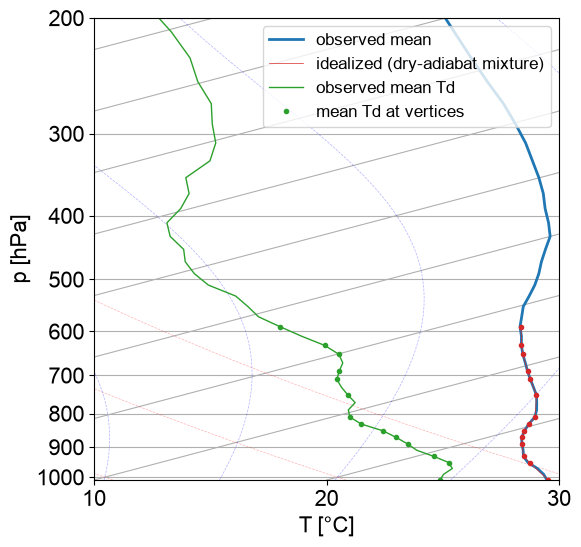

In [12]:
# plot the idealized theta profile 
# on the skew-T diagram with the histogram and the mean profile
# (needs cell 4: pc, mθ; cell 11: fms, the two dry-adiabat mixture fits)
pid = vcat((f.p for f in fms)...)                             # idealized profile: both fit sections
Tid = vcat((f.θfit for f in fms)...) .* (pid ./ 1000) .^ κ .- 273.15
# vertices: section ends and the levels where a dry adiabat with dF > 0 meets θm (kinks of θfit)
iv = [sort(unique([1; sortperm(f.θm)[f.dF .> 1e-6]; length(f.p)])) for f in fms]
pv = vcat((f.p[i] for (f, i) in zip(fms, iv))...)
Tv = vcat((f.θfit[i] for (f, i) in zip(fms, iv))...) .* (pv ./ 1000) .^ κ .- 273.15
"""
skewT_fill(fig, spec; xl, yl): metpy SkewT that fills the subplot slot `spec` (aspect "auto") for limits xl [°C],
yl [hPa], rotated so isotherms keep metpy's default data tilt, tan(55°)·80.5 °C per decade of p.
Widen the figure to widen the plot; no aspect/rotation juggling.
"""
function skewT_fill(fig, spec; xl=(-10, 40), yl=(1010, 200))
    bb = spec.get_position(fig)
    W = pyconvert(Float64, bb.width) * pyconvert(Float64, fig.get_figwidth())     # box width [in]
    H = pyconvert(Float64, bb.height) * pyconvert(Float64, fig.get_figheight())   # box height [in]
    A = (H / log10(yl[1] / yl[2])) / (W / (xl[2] - xl[1]))                        # (in per decade)/(in per °C)
    skew = cc.SkewT(fig; rotation=atand(tand(53) * 80.5 / A), aspect="auto", subplot=spec)
    skew.ax.set_xlim(xl...); skew.ax.set_ylim(yl...)
    skew
end

t = mθ .* (pc ./ 1000) .^ κ .- 273.15

plt.close("all")
fig = figure(figsize=(6, 6))
skew = skewT_fill(fig, fig.add_gridspec(1, 1)[0]; xl=(10, 30))
skew.plot(pc, t; color="C0", linewidth=2, label="observed mean")
skew.plot(pid, Tid; color="C3", linewidth=0.5, label="idealized (dry-adiabat mixture)")
skew.plot(pv, Tv; color="C3", marker=".", linestyle="none")
mTd = SondeAveraging.colstats(XTd).mean                     # observed mean Td on all levels (cell 6)
skew.plot(pc, mTd; color="C2", linewidth=1, label="observed mean Td")
Tdv = mTd[[findfirst(==(p), pc) for p in pv]]                 # at the vertices
skew.plot(pv, Tdv; color="C2", marker=".", linestyle="none", label="mean Td at vertices")
skew.plot_dry_adiabats(alpha=0.3, linewidth=0.5)
skew.plot_moist_adiabats(alpha=0.3, linewidth=0.5)
skew.ax.set_xlabel("T [°C]"; fontsize=fontsize); skew.ax.set_ylabel("p [hPa]"; fontsize=fontsize)
skew.ax.tick_params(axis="both"; labelsize=fontsize)
skew.ax.legend(; fontsize=fontsize-4)
gcf()

In [ ]:
# plot dewpoint depression and RH profile
# mean over soundings on the pressure levels (cell 6: XT, XTd); vertices of the idealized profile marked (cell 10: pv)
mDD = SondeAveraging.colstats(XT .- XTd).mean                                       # T - Td [K]
mRH = SondeAveraging.mean_on_pgrid(as, :rh; pcenters=pcenters, halfwidth=halfwidth).mean   # RH [%]
iv_ = [findfirst(==(p), pc) for p in pv]

"convert dewpoint depression to relative humidity, mixing ratio, and specific humidity using metpy"
function humidities(ph, dd; th=interpolate((pc,), mθ, Gridded(Linear())).(ph))
    t = mpc.temperature_from_potential_temperature(np.array(ph) * units.hPa, np.array(th) * units.K)
    rh = pyconvert(Vector{Float64}, mpc.relative_humidity_from_dewpoint(t, t - np.array(dd) * units.K).m_as(""))
    e = rh .* pyconvert(Vector{Float64}, mpc.saturation_vapor_pressure(t).m_as("hPa"))      # vapor pressure [hPa]
    r = mpc.mixing_ratio(np.array(e) * units.hPa, np.array(ph) * units.hPa)                  # mixing ratio [kg/kg]
    mr = pyconvert(Vector{Float64}, r.m_as(""))
    shum = pyconvert(Vector{Float64}, mpc.specific_humidity_from_mixing_ratio(r).m_as(""))
    return rh, mr, shum
end

# idealized humidity structure 
# dewpoint depression (dd) and pressure levels (ph) easiest to read off skew-T plot
ph = [1010, 1000, 950, 850, 810, 650,  500, 440, 400,  330, 210,  100,   70, 30, 10]
dd = [   4,    4, 3.5,   6,   8,   8, 14.5,  16,  16, 13.8,  12, 12.6, 13.8, 24, 31]
#      |        1       |    2    |    3     |
# 3 layers ^ for idealized moisture sources:
# sfc-850, 850-650, 650-440 hPa
rh, mr, q = humidities(ph, dd)

([0.7916577279072619, 0.790907033997371, 0.810725131565365, 0.6848326637042282, 0.5968754866157304, 0.5697363637492192, 0.31504954202053864, 0.26048083990849924, 0.24677317654068842, 0.2719474585685413, 0.24250653358823784, 0.12439161331488659, 0.10169263085584708, 0.032610483610153236, 0.007716878394946232], [0.020698630325022727, 0.02024145374894467, 0.01813269391388658, 0.012299020107902852, 0.01002847929066953, 0.005879478788999852, 0.001836770267794882, 0.001134111743107168, 0.0008265172898211841, 0.0004898193919926278, 6.113166511227359e-5, 1.1165603025909578e-6, 1.4098180114723342e-6, 1.4130937644183888e-5, 5.359062118892207e-6], [0.020278885177333516, 0.01983986601854503, 0.01780975507640484, 0.012149592031208205, 0.0099289074479488, 0.005845112573604031, 0.0018334027281748763, 0.0011328269907140904, 0.0008258347231439709, 0.0004895795864172768, 6.112792826023418e-5, 1.1165590558854404e-6, 1.4098160238883108e-6, 1.4130737963606857e-5, 5.359033399499321e-6])

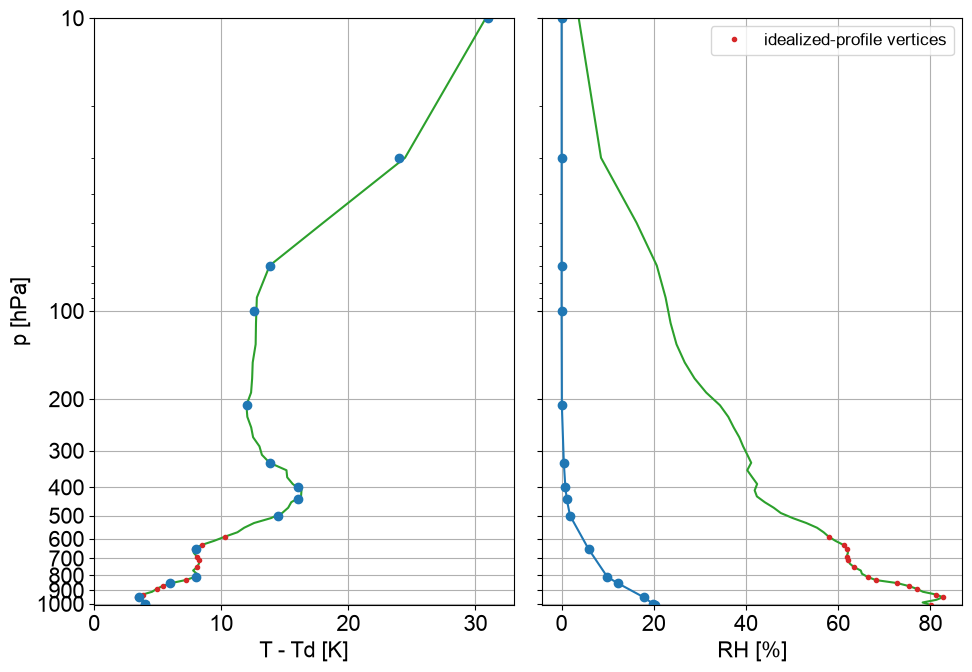

In [ ]:
# plot humidity profiles different ways
plt.close("all")
fig, axs = subplots(1, 2; figsize=(10, 7), sharey=true)
for (ax, x, lab) in zip(axs, (mDD, mRH), ("T - Td [K]", "RH [%]"))
    ax.plot(x, pc; color="C2", linewidth=1.5)
    ax.plot(x[iv_], pv; color="C3", marker=".", linestyle="none", label="idealized-profile vertices")
    ax.set_xlabel(lab; fontsize=fontsize)
    ax.tick_params(axis="both"; labelsize=fontsize)
end
axs[0].set_yscale("log"); axs[0].set_ylim(1010, 100)
ticks = [1000, 900, 800, 700, 600, 500, 400, 300, 200, 100, 10]
axs[0].set_yticks(ticks); axs[0].set_yticklabels(string.(ticks))
axs[0].set_ylabel("p [hPa]"; fontsize=fontsize)
axs[0].set_xlim([0, 33])
axs[0].grid(true); axs[1].grid(true)
axs[0].plot(dd, ph, "o")
axs[1].plot(1e3*q, ph, "o-")
axs[1].legend(; fontsize=fontsize-4)
tight_layout()
gcf()

ph = [1010, 1000, 950, 850, 810, 650, 500, 440, 400, 330, 210, 100, 70, 30, 10]
uh = [2.6, 3.1, 6.6, 7.1, 5.9, 3.2, 4.6, 3.8, 2.9, 1.5, -3.6, -16.2, -9.3, -13.7, -18.6]
vh = [-1.1, -1.0, -1.5, -1.8, -1.9, -1.4, -1.3, -0.8, -0.6, -0.4, 1.3, -0.1, -0.1, -0.3, 1.0]


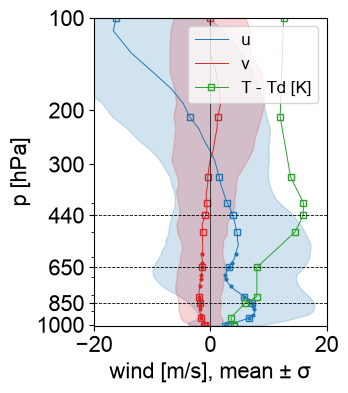

In [26]:
# plot wind u,v profiles
# do any stick to sfc-850, 850-650, 650-440 hPa?
plt.close("all")
fig, ax = subplots(figsize=(3, 4))
wh = Dict{Symbol,Vector{Float64}}()                             # idealized wind at the humidity vertices ph
for (f, c) in ((:u, "C0"), (:v, "C3"))
    m, s, n = SondeAveraging.mean_on_pgrid(as, f; pcenters=pcenters, halfwidth=halfwidth)
    ax.fill_betweenx(pc, m .- s, m .+ s; color=c, alpha=0.2)
    ax.plot(m, pc; color=c, linewidth=0.7, label=string(f))
    ax.plot(m[[findfirst(==(p), pc) for p in pv]], pv; color=c, marker=".", markersize=4, linestyle="none")   # θ vertices (cell 10)
    wh[f] = interpolate((pc,), m, Gridded(Linear())).(ph)
    ax.plot(wh[f], ph; color=c, marker="s", markersize=4, markerfacecolor="none", linestyle="none")   # humidity vertices (cell 12: ph)
end
ax.plot(dd, ph; color="C2", marker="s", markersize=4, markerfacecolor="none", linewidth=0.7, label="T - Td [K]")  # idealized (cell 12)
ax.plot(1e3 .* q, ph; color="C4", marker="^", markersize=4, markerfacecolor="none", linewidth=0.7, label="q [g/kg]")  # idealized (cell 12)
println("ph = ", ph)
println("uh = ", round.(wh[:u]; digits=1))
println("vh = ", round.(wh[:v]; digits=1))
# idealize wind on the humidity vertices:
uh = [2.6, 3.1, 6.6, 7.1, 5.9, 3.2, 4.6, 3.8, 2.9, 1.5, -3.6, -16.2, -9.3, -13.7, -18.6]
vh = [-1.1, -1.0, -1.5, -1.8, -1.9, -1.4, -1.3, -0.8, -0.6, -0.4, 1.3, -0.1, -0.1, -0.3, 1.0]

for pl in (850, 650, 440); ax.axhline(pl; color="k", linewidth=0.6, linestyle="--"); end
ax.axvline(0; color="k", linewidth=0.5)
ax.set_yscale("log"); ax.set_ylim(1010, 100)
ticks = [1000, 850, 650, 440, 300, 200, 100]
ax.set_yticks(ticks); ax.set_yticklabels(string.(ticks))
ax.set_xlim(-20, 20)
ax.set_xlabel("wind [m/s], mean ± σ"; fontsize=fontsize); ax.set_ylabel("p [hPa]"; fontsize=fontsize)
ax.tick_params(axis="both"; labelsize=fontsize)
ax.legend(; fontsize=fontsize-4)
gcf()


linear: θes(590) = 347.88 K, dθes/dp = -0.803 K/(100 hPa);  above: B = 2.417 K/(100 hPa), A = 0.001 K, H = 30.0 hPa
rms misfit θes 2.93 K, θ 2.77 K


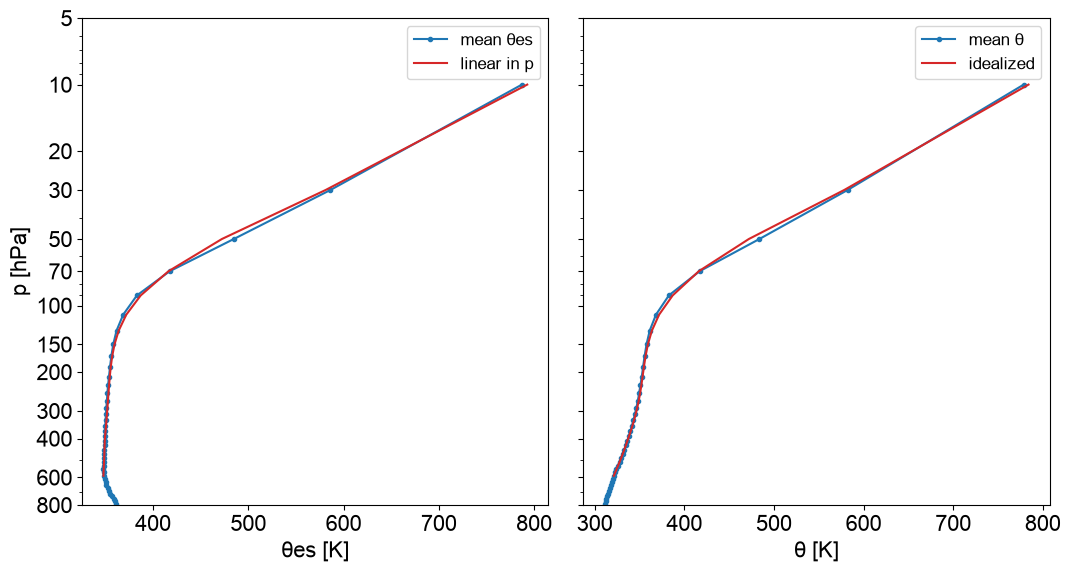

In [85]:
# idealize the mean profile above 590 hPa: θes linear in p (stable relative to a moist adiabat when θes increases
# upward), θ from the moist adiabats of idealized_sounding.jl (needs cell 4: pc, mθ; cell 7: θes)
include("idealized_sounding.jl")
pa, pq, pz = 590.0, 400.0, 10.0                              # linear pq ≤ p ≤ pa, linear + exponential pz ≤ p < pq
k = findall(pz .<= pc .<= pa)
kl, kq = findall(pq .<= pc .<= pa), findall(pz .<= pc .< pq)
b0, b1 = [ones(length(kl)) (pc[kl] .- pa)] \ θes[kl]          # θes ≈ b0 + b1 (p - pa)
θq = b0 + b1 * (pq - pa)                                      # continuous at pq
# θes ≈ θq + B (pq - p) + A (exp((pq - p)/H) - 1), continuous at pq: A, B by least squares for each H, best H from a scan
function efit(H)
    X = [(pq .- pc[kq]) (exp.((pq .- pc[kq]) ./ H) .- 1)]
    B, A = X \ (θes[kq] .- θq)
    (A=A, B=B, H=H, r=sum(abs2, X * [B, A] .- (θes[kq] .- θq)))
end
ef = argmin(f -> f.r, efit.(10.0:5.0:500.0))
θes_fit = [p >= pq ? b0 + b1 * (p - pa) : θq + ef.B * (pq - p) + ef.A * (exp((pq - p) / ef.H) - 1) for p in pc[k]]
θ_fit = θ_moist.(θes_fit, pc[k])
println("linear: θes(590) = ", round(b0; digits=2), " K, dθes/dp = ", round(100b1; digits=3), " K/(100 hPa);  ",
        "above: B = ", round(100ef.B; digits=3), " K/(100 hPa), A = ", round(ef.A; digits=3), " K, H = ", ef.H, " hPa")
println("rms misfit θes ", round(sqrt(mean((θes_fit .- θes[k]) .^ 2)); digits=2), " K, θ ", round(sqrt(mean((θ_fit .- mθ[k]) .^ 2)); digits=2), " K")

plt.close("all")
fig, axs = subplots(1, 2; figsize=(11, 6), sharey=true)
kp = findall(5 .<= pc .<= 800)                              # plotted levels
axs[0].plot(θes[kp], pc[kp]; color="C0", marker=".", label="mean θes")
axs[0].plot(θes_fit, pc[k]; color="C3", label="linear in p")
axs[1].plot(mθ[kp], pc[kp]; color="C0", marker=".", label="mean θ")
axs[1].plot(θ_fit, pc[k]; color="C3", label="idealized")
axs[0].set_yscale("log"); axs[0].set_ylim(800, 5)
ticks = [800, 600, 400, 300, 200, 150, 100, 70, 50, 30, 20, 10, 5]
axs[0].set_yticks(ticks); axs[0].set_yticklabels(string.(ticks))
axs[0].set_ylabel("p [hPa]"; fontsize=fontsize)
axs[0].set_xlabel("θes [K]"; fontsize=fontsize); axs[1].set_xlabel("θ [K]"; fontsize=fontsize)
# axs[0].set_yscale("linear")
for a in axs; a.legend(; fontsize=fontsize-4); a.tick_params(axis="both"; labelsize=fontsize); end
tight_layout()
gcf()

In [ ]:
# θ histograms: 2023 vs. all other years, same bins as above (needs cell 3: pcenters, halfwidth, Tedge, Pedge, cmap)
yr = [year(p.time) for p in as]
for y in sort(unique(yr)); println(y, ": ", count(==(y), yr), " soundings"); end

groups = (("2023", as[yr .== 2023]), ("other years", as[yr .!= 2023]))
hg = map(groups) do (name, ps)
    (name=name, n=length(ps),
     h=hist_field(ps, :θ; dx=0.2, xlims=(280.0, 400.0), pcenters=pcenters, halfwidth=halfwidth))
end

plt.close("all")
fig = figure(figsize=(14, 7))
for (i, g) in enumerate(hg)
    skew = cc.SkewT(fig; rotation=55, subplot=(1, 2, i))
    C = float.(g.h.H) ./ max(g.n, 1)              # fraction of this group's soundings per bin, so the groups compare
    C[C .== 0] .= NaN
    m = skew.ax.pcolormesh(Tedge, Pedge, collect(C'); cmap=cmap, vmin=0)
    skew.plot_dry_adiabats(alpha=0.3, linewidth=0.5)
    skew.plot_moist_adiabats(alpha=0.3, linewidth=0.5)
    skew.ax.set_ylim(1010, 200); skew.ax.set_xlim(20, 40)
    fig.colorbar(m; ax=skew.ax, label="fraction of soundings")
    skew.ax.set_title("$(g.name) (n = $(g.n))"; fontsize=fontsize)
    skew.ax.set_xlabel("θ (K)"; fontsize=fontsize)
    skew.ax.tick_params(axis="both"; labelsize=fontsize)
end
tight_layout()
gcf()

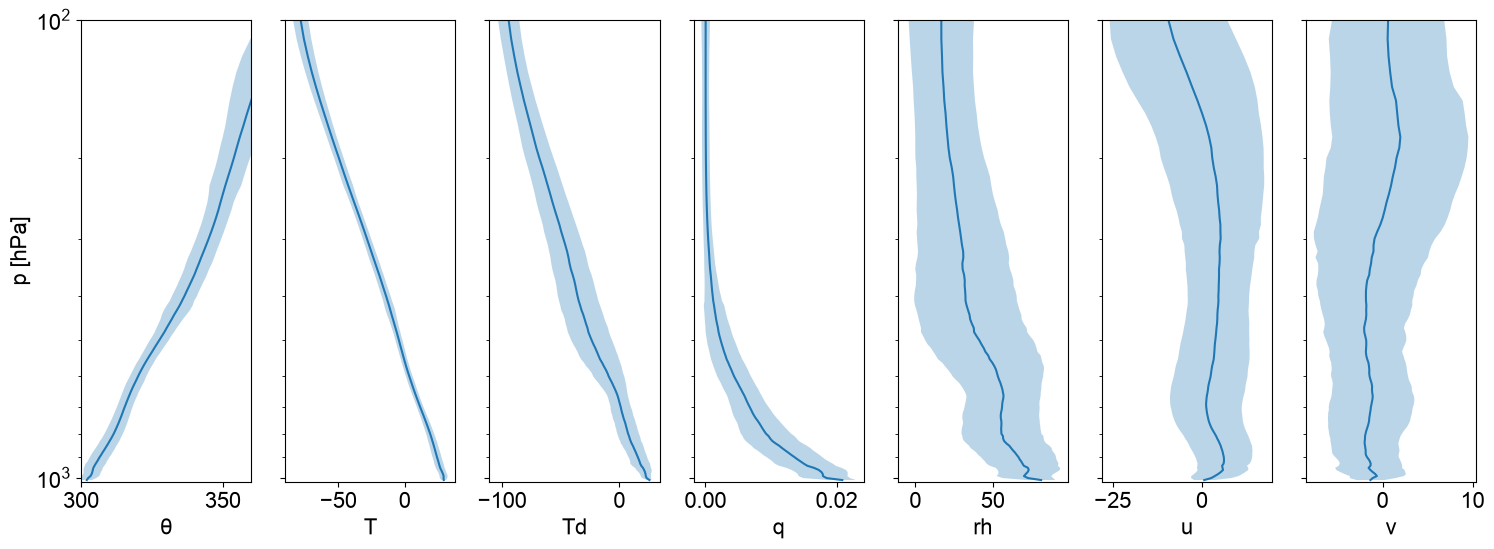

In [5]:
# mean on the 10 hPa grid: average higher-resolution, interpolate lower-resolution soundings
fields = (:θ, :T, :Td, :q, :rh, :u, :v)
ms = map(f -> SondeAveraging.mean_on_pgrid(as, f), fields)

plt.close("all")
fig, axs = subplots(1, length(fields); figsize=(18, 6), sharey=true)
for (ax, f, m) in zip(axs, fields, ms)
    pc = collect(m.pcenters)
    ax.fill_betweenx(pc, m.mean .- m.std, m.mean .+ m.std; alpha=0.3)
    ax.plot(m.mean, pc)
    ax.set_xlabel(string(f); fontsize=fontsize)
    ax.tick_params(axis="both"; labelsize=fontsize)
    ax.set_yscale("log")
end
axs[0].set_ylabel("p [hPa]"; fontsize=fontsize); axs[0].set_ylim(1020, 100)
axs[0].set_xlim(300, 360)
gcf()

236 soundings used, 197 rejected (too coarse or a layer not found)
surface  182.0 m
SCI base 1157.0 m
SCI top  1481.0 m
MML base 3796.0 m
MML top  5014.0 m
MI top   5540.0 m


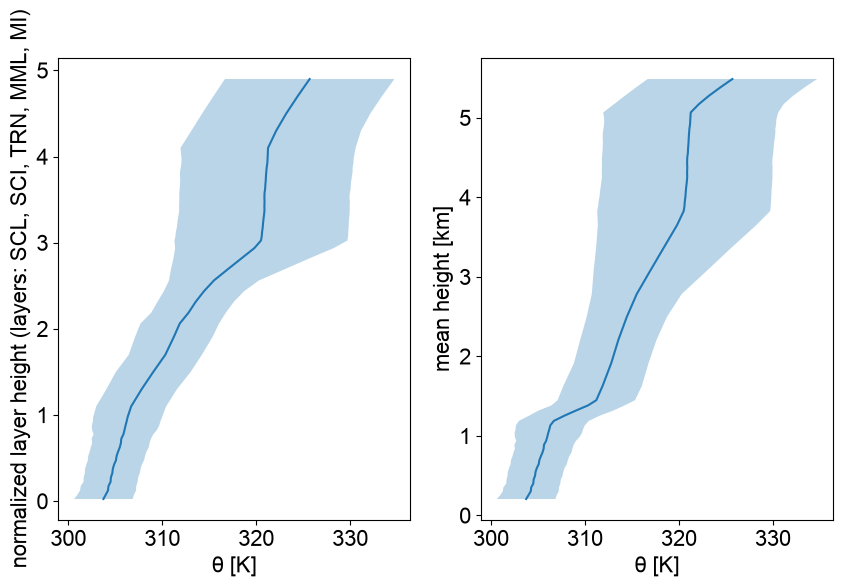

In [6]:
# composite in layers: shallow cumulus layer | SCI | transition | MML | MI (normalized height)
c = SondeAveraging.composite_layers(as, (:θ, :T, :Td, :q, :u, :v))
println(length(c.ok), " soundings used, ", c.nrejected, " rejected (too coarse or a layer not found)")
for (k, name) in enumerate(("surface", "SCI base", "SCI top", "MML base", "MML top", "MI top"))
    println(rpad(name, 9), round(mean(c.edges[:, k]); digits=0), " m")
end

plt.close("all")
fig, axs = subplots(1, 2; figsize=(10, 6))
axs[0].fill_betweenx(c.ζ, c.mean.θ .- c.std.θ, c.mean.θ .+ c.std.θ; alpha=0.3)
axs[0].plot(c.mean.θ, c.ζ)
axs[0].set_yticks(0:length(SondeAveraging.LAYERS)); axs[0].set_ylabel("normalized layer height (layers: $(join(SondeAveraging.LAYERS, ", ")))"; fontsize=fontsize)
axs[1].fill_betweenx(c.zmean ./ 1000, c.mean.θ .- c.std.θ, c.mean.θ .+ c.std.θ; alpha=0.3)
axs[1].plot(c.mean.θ, c.zmean ./ 1000)
axs[1].set_ylabel("mean height [km]"; fontsize=fontsize)
for ax in axs
    ax.set_xlabel("θ [K]"; fontsize=fontsize)
    ax.tick_params(axis="both"; labelsize=fontsize)
end
gcf()

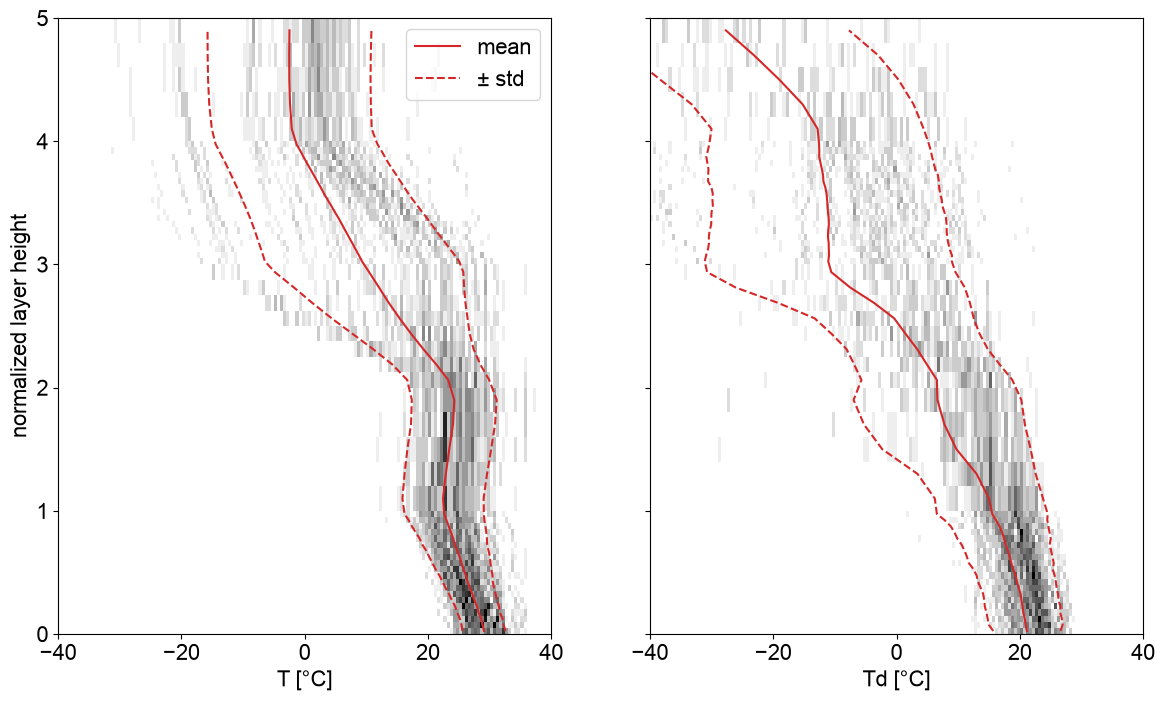

In [7]:
# histograms of T and Td in the composite (normalized) height bins, one realization per sounding
Tbin = 0.5                                   # bin width [K]
Tlims = (-80.0, 40.0)
nper = SondeAveraging.DEFAULT_NPER
# ζ edges of the composite levels: layer l spans l-1 to l, with nper[l] levels
ζedges = vcat([(l - 1) .+ (0:n-1) ./ n for (l, n) in enumerate(nper)]..., length(nper))

hc = map((:T, :Td)) do f
    H, Tedges = SondeAveraging.hist_pgrid(c.X[f]; dx=Tbin, xlims=Tlims)
    (H=H, Tedges=Tedges)
end

plt.close("all")
fig, axs = subplots(1, 2; figsize=(14, 8), sharey=true)
for (ax, f, h) in zip(axs, (:T, :Td), hc)
    C = float.(h.H); C[C .== 0] .= NaN
    m = ax.pcolormesh(h.Tedges, ζedges, collect(C'); cmap=cmap, vmin=1)
    ax.plot(c.mean[f], c.ζ; color="C3", label="mean")                       # mean ± std
    ax.plot(c.mean[f] .- c.std[f], c.ζ; color="C3", linestyle="--", label="± std")
    ax.plot(c.mean[f] .+ c.std[f], c.ζ; color="C3", linestyle="--")
    ax.set_xlim(-40, 40)
    ax.set_xlabel(string(f, " [°C]"); fontsize=fontsize)
    ax.set_yticks(0:length(nper))
    ax.tick_params(axis="both"; labelsize=fontsize)
end
axs[0].set_ylabel("normalized layer height"; fontsize=fontsize)
axs[0].legend(; fontsize=fontsize)
gcf()

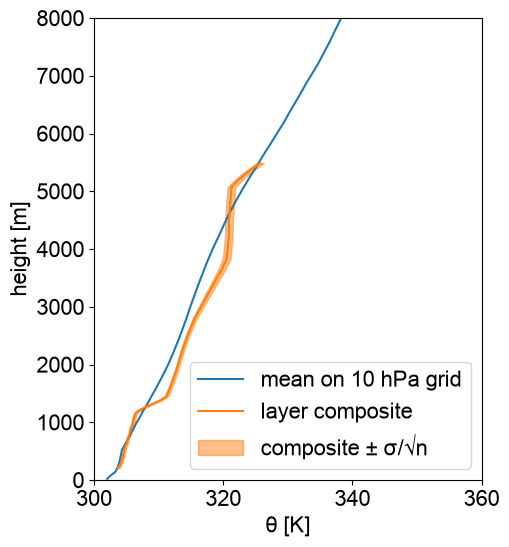

In [8]:
# compare mean θ from methods 2 and 3 against mean height
mz = SondeAveraging.mean_on_pgrid(as, :z)
mθ = ms[1]
plt.close("all")
fig, ax = subplots(figsize=(5, 6))
ax.plot(mθ.mean, mz.mean; label="mean on 10 hPa grid")
ax.plot(c.mean[:θ], c.zmean; label="layer composite")
# ax.plot(c.mean[:θ] .- c.std[:θ], c.zmean; linestyle="--", linewidth=1, label="layer composite -1σ")
# ax.plot(c.mean[:θ] .+ c.std[:θ], c.zmean; linestyle="--", linewidth=1, label="layer composite +1σ")
# standard deviation of the mean (standard error): σ/√n over the n soundings at each level
sem = c.std[:θ] ./ sqrt.(c.n[:θ])
ax.fill_betweenx(c.zmean, c.mean[:θ] .- sem, c.mean[:θ] .+ sem; color="C1", alpha=0.5, label="composite ± σ/√n")
ax.set_xlabel("θ [K]"; fontsize=fontsize); ax.set_ylabel("height [m]"; fontsize=fontsize)
ax.set_ylim(0, 8000); ax.legend(; fontsize=fontsize)
ax.set_xlim(300, 360)
ax.tick_params(axis="both"; labelsize=fontsize)
gcf()

In [9]:
# composite profile on a skew-T log-p diagram
cp = SondeAveraging.composite_layers(as, (:p, :T, :Td))     # mean p, T, Td at the composite levels
p, T, Td = cp.mean.p, cp.mean.T, cp.mean.Td

plt.close("all")
fig = figure(figsize=(8, 9))
skew = cc.SkewT(fig; rotation=45)
skew.plot(p, mpc.temperature_from_potential_temperature(p, mz.θ);
    color="C3", linewidth=2, label="T")
skew.plot(p, T; color="C3", linewidth=2, label="T")
skew.plot(p, Td; color="C0", linewidth=2, label="Td")
# standard deviation of the mean, σ/√n over the n soundings at each level
semT, semTd = cp.std.T ./ sqrt.(cp.n.T), cp.std.Td ./ sqrt.(cp.n.Td)
skew.ax.fill_betweenx(p, T .- semT, T .+ semT; color="C3", alpha=0.3, label="T ± σ/√n")
skew.ax.fill_betweenx(p, Td .- semTd, Td .+ semTd; color="C0", alpha=0.3, label="Td ± σ/√n")
skew.plot_dry_adiabats(alpha=0.3, linewidth=0.5)
skew.plot_moist_adiabats(alpha=0.3, linewidth=0.5)
skew.plot_mixing_lines(alpha=0.3, linewidth=0.5)
skew.ax.set_ylim(1010, 200); skew.ax.set_xlim(-40, 40)
skew.ax.set_xlabel("T, Td [°C]"; fontsize=fontsize); skew.ax.set_ylabel("p [hPa]"; fontsize=fontsize)
skew.ax.tick_params(axis="both"; labelsize=fontsize)
skew.ax.legend(; fontsize=fontsize)
gcf()

FieldError: FieldError: type NamedTuple has no field `θ`, available fields: `mean`, `std`, `n`, `X`, `pcenters`